In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ice-cream-sales-dataset' dataset.
Path to dataset files: /kaggle/input/ice-cream-sales-dataset


In [ ]:
import os
import pandas as pd

# Listar os arquivos no diretório do dataset
files = os.listdir(path)
print("Arquivos encontrados:", files)

# Carregar o primeiro arquivo CSV que encontrar
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"\nExibindo as primeiras linhas de: {csv_files[0]}")
    display(df.head())
else:
    print("Nenhum arquivo CSV encontrado no diretório do dataset.")

Arquivos encontrados: ['Ice Cream.csv']

Exibindo as primeiras linhas de: Ice Cream.csv


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


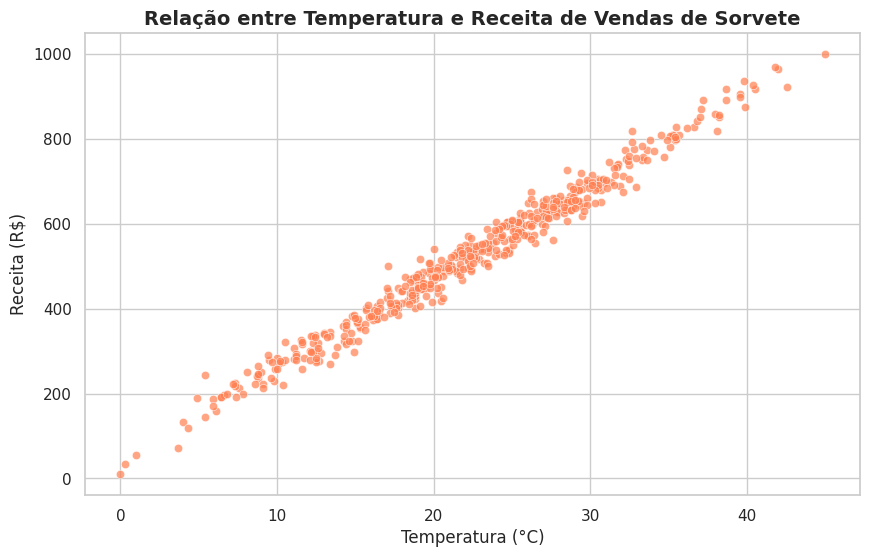

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Temperature', y='Revenue', color='coral', alpha=0.7)

# Adicionar títulos e rótulos aos eixos
plt.title('Relação entre Temperatura e Receita de Vendas de Sorvete', fontsize=14, fontweight='bold')
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Receita (R$)', fontsize=12)

# Exibir o gráfico
plt.show()

Coeficiente (Inclinação): 21.38
Intercepto (Viés): 46.18
R² Score (Acurácia): 0.9772
Erro Quadrático Médio (MSE): 652.49


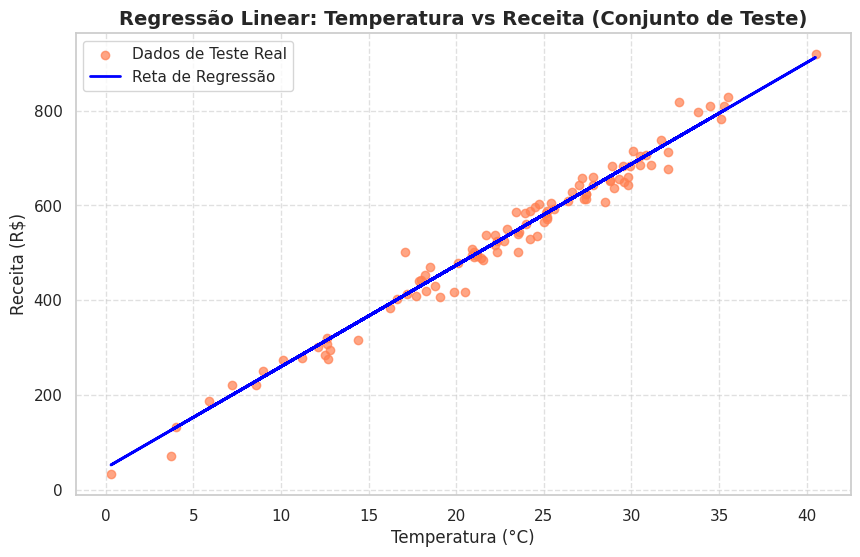

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Preparar as variáveis independente (X) e dependente (y)
X = df[['Temperature']]
y = df['Revenue']

# 2. Dividir os dados em conjuntos de treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Criar e treinar o modelo de Regressão Linear
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Fazer previsões no conjunto de teste
y_pred = model.predict(X_test)

# 5. Avaliar o modelo
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"Coeficiente (Inclinação): {model.coef_[0]:.2f}")
print(f"Intercepto (Viés): {model.intercept_:.2f}")
print(f"R² Score (Acurácia): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")

# 6. Plotar a reta de regressão sobre os dados de teste
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='coral', label='Dados de Teste Real', alpha=0.7)
plt.plot(X_test, y_pred, color='blue', linewidth=2, label='Reta de Regressão')
plt.title('Regressão Linear: Temperatura vs Receita (Conjunto de Teste)', fontsize=14, fontweight='bold')
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Receita (R$)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()